In [61]:

# 1. Import required libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

In [62]:
# 2. Dataset paths
train_path = r"D:\Downloads\DL DATASET\cats_and_dogs_filtered\train"
val_path = r"D:\Downloads\DL DATASET\cats_and_dogs_filtered\validation"

In [63]:
# 3. Load and preprocess images
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)



In [64]:
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_data = val_datagen.flow_from_directory(
    val_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [65]:
# 4. Load pre-trained MobileNetV2 model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pre-trained layers
base_model.trainable = False


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 8s 1us/step


In [66]:
# 5. Build transfer learning model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# 6. Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [67]:
# 7. Train the model
history = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data
)

C:\Users\19shi\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.9655 - loss: 0.0932 - val_accuracy: 0.9850 - val_loss: 0.0407
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 60s 948ms/step - accuracy: 0.9875 - loss: 0.0392 - val_accuracy: 0.9860 - val_loss: 0.0440
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 59s 939ms/step - accuracy: 0.9930 - loss: 0.0196 - val_accuracy: 0.9830 - val_loss: 0.0462
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 59s 936ms/step - accuracy: 0.9950 - loss: 0.0134 - val_accuracy: 0.9880 - val_loss: 0.0447
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 82s 938ms/step - accuracy: 0.9975 - loss: 0.0096 - val_accuracy: 0.9850 - val_loss: 0.0492
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 60s 950ms/step - accuracy: 0.9995 - loss: 0.0046 - val_accuracy: 0.9860 - val_loss: 0.0560
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 81s 938ms/step - accuracy: 0.9990 - loss: 0.0033 - val_accuracy: 0.9810 - val_loss: 0.0672
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 59s 943ms/step - accuracy: 0.9995 - loss: 0.0031 - val_accurac

In [68]:
# 8. Evaluate model
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")


32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 611ms/step - accuracy: 0.9840 - loss: 0.0583    
Validation Loss: 0.058336999267339706
Validation Accuracy: 98.4000027179718 %


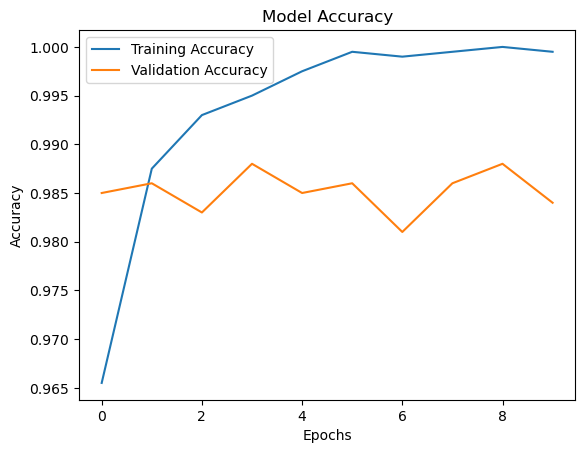

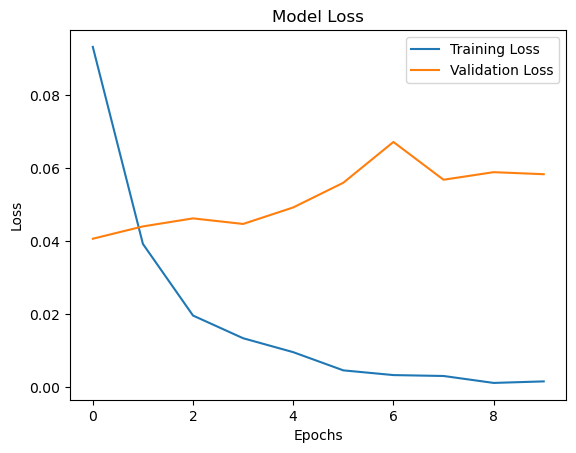

In [69]:
# 9. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 10. Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


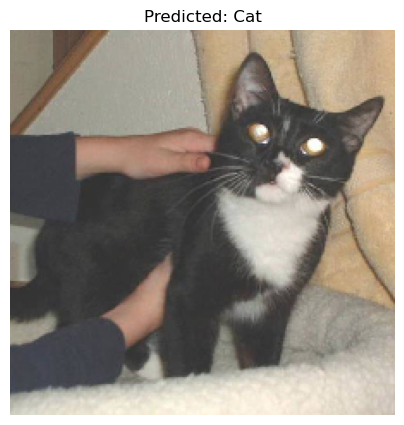

Predicted Class: Cat


In [70]:
# Display one image and its prediction
images, labels = next(val_data)

prediction = model.predict(images[:1])

if prediction[0][0] >= 0.5:
    predicted_class = "Dog"
else:
    predicted_class = "Cat"

plt.figure(figsize=(5, 5))
plt.imshow(images[0] / 2 + 0.5)
plt.title("Predicted: " + predicted_class)
plt.axis('off')
plt.show()

print("Predicted Class:", predicted_class)
